# 5. Speed

The two-parameter analysis of notebook 2 (source-frame primary mass $m_1^{\rm src}$ and redshift $z$, 3,517 masses,
$1600 \times 1600$ grid) with the settings for speed:

* all tables are kept on the GPU (about 40 GB), so nothing is copied while segments are analyzed;
* each template visits 64 arrival times with the largest matched-filter output plus 64 drawn at random, instead of
  1024 + 1024;
* the segments are analyzed in batches of 16.

We first check against `bilby`/`dynesty` that these settings give the same posteriors, then time 843 segments.
The tables come from Zenodo (see the README); `../data/segments/benchmark.npz` too.

In [1]:
import sys
sys.path.insert(0, '../src')

import time
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp
import exmarg.gpu as gpu
from exmarg import figstyle

fast = dict(n_loud=64, n_random=64, block=64, resident=True)
print('GPU:', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())

start = time.time()
store = gpu.load_redshift_store('../tables/redshift')
print('tables read in %.0f s (once)' % (time.time() - start))

GPU: NVIDIA H100


tables read in 30 s (once)


## The same posteriors as nested sampling

12 segments with one merger each at SNR 6 to 9, for which `bilby` sampled $m_1^{\rm src}$, $z$, the distance and the
extrinsic parameters (2000 live points, 128 CPU cores each; settings in `../scripts/run_bilby.py`).

In [2]:
segments = '../data/segments/bilby_comparison.npz'
snr = np.load(segments)['snr']
bilby = np.load('../data/results/bilby_2p_comparison.npz')

templates = gpu.mass_bank('../data/banks/two_parameters.npy', segments)
gpu.pe_redshift(segments, templates, store, rows=[0], **fast)        # compiles the kernels, copies the tables once

start = time.time()
result = gpu.pe_redshift(segments, templates, store, chunk=12, **fast)
seconds = time.time() - start
print('12 segments in %.1f s: %.2f s per segment' % (seconds, seconds / 12))
print('bilby: %.0f to %.0f s per segment on 128 cores' % (bilby['wall_seconds'].min(), bilby['wall_seconds'].max()))
print()
print('segment   SNR   ln B (this work)   ln B (bilby)')
for k in [3, 4, 5, 6, 7, 11]:
    print('%7d   %4.1f   %16.2f   %7.2f +- %.2f'
          % (k, snr[k], result['ln_b'][k], bilby['e%d_ln_b' % k], bilby['e%d_ln_b_err' % k]))

12 segments in 1.4 s: 0.12 s per segment
bilby: 76 to 224 s per segment on 128 cores

segment   SNR   ln B (this work)   ln B (bilby)
      3    6.6               0.96      0.95 +- 0.09
      4    7.0               0.09      0.08 +- 0.05
      5    6.0              -0.01     -0.01 +- 0.01
      6    6.0               0.03      0.03 +- 0.02
      7    6.4               0.01      0.01 +- 0.03
     11    8.7               6.36      6.45 +- 0.09


The posteriors of two of these segments in the style of Fig. 21: ours from the run above and the `bilby` samples.
The prior is uniform in $M_{\rm det} = 2 m_1^{\rm src}(1+z)$ between 10 and 500 $M_\odot$ and proportional to $D_L^2$.
The panels of the sky position and the orientation belong to the sampler only.

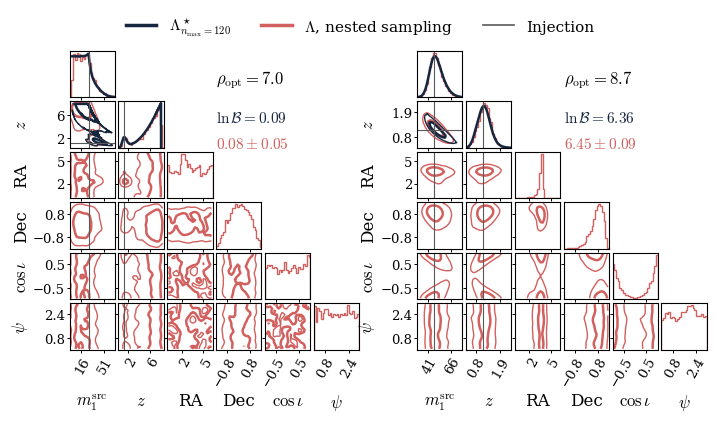

In [3]:
from astropy.cosmology import Planck18
import figures_validation as figures

m1, z = result['m1'], result['z']
DL = Planck18.luminosity_distance(z).value
prior = (1 + z) * DL ** 2 * np.gradient(DL, z)
M_det = 2 * m1[:, None] * (1 + z[None, :])
inside = (M_det >= 10) & (M_det <= 500)
truth = np.load(segments)

shown = {}
for e, k in enumerate([4, 11]):
    lp = np.where(inside, result['ln_lambda'][k] + np.log(prior)[None, :], -np.inf)
    finite = np.isfinite(lp)
    posterior = np.zeros_like(lp)
    posterior[finite] = np.exp(lp[finite] - lp[finite].max())
    posterior = posterior * np.gradient(m1)[:, None] * np.gradient(z)[None, :]
    # bilby samples inside the grid of our analysis
    keep = ((bilby['e%d_m1' % k] >= m1[0]) & (bilby['e%d_m1' % k] <= m1[-1])
            & (bilby['e%d_z' % k] >= z[0]) & (bilby['e%d_z' % k] <= z[-1]))
    shown.update({'e%d_m1_grid' % e: m1, 'e%d_z_grid' % e: z, 'e%d_ours_posterior' % e: posterior / posterior.sum(),
                  'e%d_true_m1' % e: truth['true_m1_source'][k], 'e%d_true_z' % e: truth['true_z'][k],
                  'e%d_lnB_ours' % e: result['ln_b'][k], 'e%d_lnB_bilby' % e: bilby['e%d_ln_b' % k],
                  'e%d_lnB_bilby_err' % e: bilby['e%d_ln_b_err' % k], 'e%d_rho' % e: snr[k]})
    for name in ('m1', 'z', 'ra', 'dec', 'cos_iota', 'psi'):
        shown['e%d_bilby_%s' % (e, name)] = bilby['e%d_%s' % (k, name)][keep]

figures.fig_corner_2p(shown, shown)

## Time per segment on 843 segments

843 simulated 8 s segments with one merger each, about 80 per SNR bin, up to SNR 15 (the series converges for
$n_{\max} = 120 > {\rm SNR}^2/2$). The segments are sorted by SNR and analyzed in batches of 16.

In [4]:
segments = '../data/segments/benchmark.npz'
snr = np.load(segments)['snr']
templates = gpu.mass_bank('../data/banks/two_parameters.npy', segments)
gpu.pe_redshift(segments, templates, store, rows=[0], **fast)

order = np.argsort(snr)
batches = [np.sort(order[i:i + 16]) for i in range(0, order.size, 16)]
per_segment, batch_snr = [], []
start_all = time.time()
for b in batches:
    start = time.time()
    gpu.pe_redshift(segments, templates, store, rows=b, chunk=16, **fast)
    per_segment.append((time.time() - start) / b.size)
    batch_snr.append(np.median(snr[b]))
total = time.time() - start_all
per_segment, batch_snr = np.array(per_segment), np.array(batch_snr)
print('%d segments in %.0f s: %.3f s per segment (batches from %.3f to %.3f s per segment)'
      % (snr.size, total, total / snr.size, per_segment.min(), per_segment.max()))
print('%.0f segments per GPU hour' % (3600 * snr.size / total))

843 segments in 99 s: 0.118 s per segment (batches from 0.116 to 0.120 s per segment)
30593 segments per GPU hour


## Against nested sampling

The wall time of one segment against its SNR. Ours is one GPU for one batch divided by the batch size; the `bilby` runs
used 32 CPU cores (three parameters), 28 cores (two parameters, the segments of Fig. 21) and 128 cores (two parameters,
the 12 segments above).

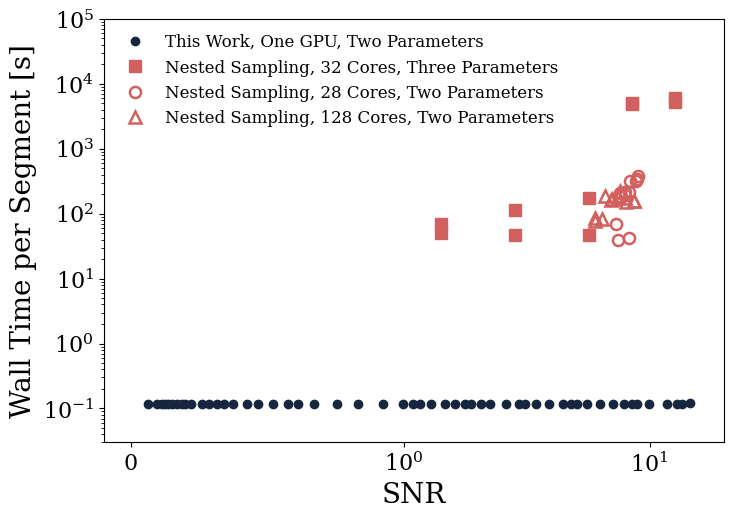

this work: 0.118 s per segment at every SNR
bilby, the 12 segments above: median 159 s on 128 cores, 1355 times longer


In [5]:
runs = np.load('../data/results/bilby_runs.npz')
three = np.load('../data/segments/three_parameters.npz')['snr'][:len(runs['three_parameters_wall_seconds'])]
two = np.load('../data/segments/two_parameters.npz')['snr']
comparison = np.load('../data/segments/bilby_comparison.npz')['snr']
valid = three <= 15

figstyle.apply()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(batch_snr, per_segment, 'o', color=figstyle.NAVY, ms=6, label='This Work, One GPU, Two Parameters')
ax.plot(three[valid], runs['three_parameters_wall_seconds'][valid], 's', color=figstyle.RED, ms=8,
        label='Nested Sampling, 32 Cores, Three Parameters')
ax.plot(two, runs['two_parameters_wall_seconds'][:two.size], 'o', mfc='none', mec=figstyle.RED, mew=1.8, ms=8,
        label='Nested Sampling, 28 Cores, Two Parameters')
ax.plot(comparison, bilby['wall_seconds'], '^', mfc='none', mec=figstyle.RED, mew=1.8, ms=8,
        label='Nested Sampling, 128 Cores, Two Parameters')
ax.set_xscale('symlog', linthresh=1)
ax.set_xlim(-0.1, 20)
ax.set_yscale('log')
ax.set_ylim(0.03, 1e5)
ax.set_xlabel('SNR')
ax.set_ylabel('Wall Time per Segment [s]')
ax.legend(frameon=False, loc='upper left', fontsize=12)
plt.show()

ours = total / snr.size
print('this work: %.3f s per segment at every SNR' % ours)
print('bilby, the 12 segments above: median %.0f s on 128 cores, %.0f times longer'
      % (np.median(bilby['wall_seconds']), np.median(bilby['wall_seconds']) / ours))